## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [1]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/heart_disease.csv"


## Cell 2 — Import Libraries

In [4]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [5]:
# TODO: Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(DATA_PATH, header=None, names=columns, na_values="?")

df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [7]:
print("shape:", df.shape)

shape: (303, 14)


In [8]:
print("cols", df.dtypes)

cols age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


In [10]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [11]:
print("target values:", df["target"].unique())
print("Target value counts:", df["target"].value_counts().sort_index())

target values: [0 2 1 3 4]
Target value counts: target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [13]:
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


- samples and features: 303 samples, 13 features (plus 1 target column)

- column names and data types: all 13 feature columns (age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal) are float64. target column is int64.

- first 5 rows: rows show patient data like age, sex, chest pain type (cp), resting blood pressure (trestbps), cholesterol (chol), and other health measurements. values are mostly numbers, some are 0/1 codes (like sex), some are category codes (like cp).

- descriptive statistics: age ranges from 29 to 77 (mean ~54). chol ranges from 126 to 564. ca has only 299 non-null values and thal has 301, so these two columns have missing values. columns are on very different scales (like chol vs oldpeak), so scaling will be needed later.

- target variable: target takes values 0, 1, 2, 3, 4. 0 means no heart disease, and 1-4 mean heart disease is present with increasing severity. most samples (164) are 0, so this is not a plain binary target yet.

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
target
0    54.125413
1    18.151815
2    11.881188
3    11.551155
4     4.290429
Name: proportion, dtype: float64


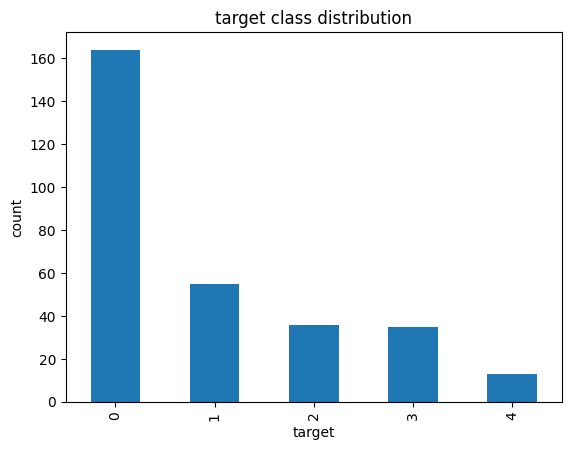

In [14]:
print(df["target"].value_counts().sort_index())

print(df["target"].value_counts(normalize=True).sort_index() * 100)

df["target"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("target")
plt.ylabel("count")
plt.title("target class distribution")
plt.show()

the dataset is imbalanced. class 0 (no disease) has 164 samples (54%), while classes 1-4 each have far fewer (55, 36, 35, and 13 samples). if we binarize target into disease/no disease, its closer to balanced (164 vs 139), but the raw 5-class version is clearly imbalanced, especially class 4 with only 13 samples.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [15]:
print(df.isnull().sum())

print("\nduplicate rows:", df.duplicated().sum())

print("\ndtypes:\n", df.dtypes)

print("\nunique values per column:\n", df.nunique())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

duplicate rows: 0

dtypes:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

unique values per column:
 age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        5
dtype: int64


ca and thal have missing values (4 and 2 rows). since both are small counts out of 303 rows, i will impute them rather than drop rows. ca and thal are categorical/ordinal, so i will use the most frequent value (mode) to fill them in, using sklearn's simpleimputer with strategy="most_frequent".

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

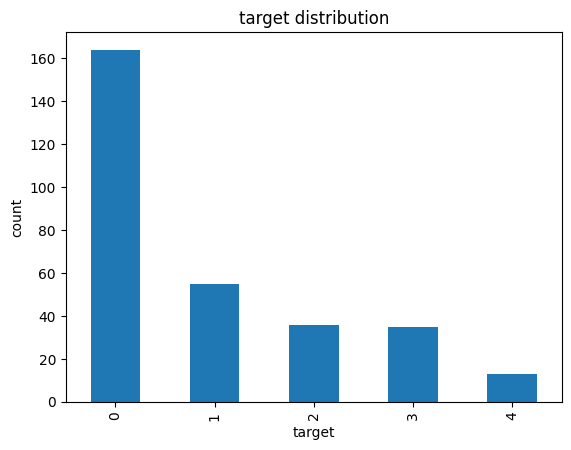

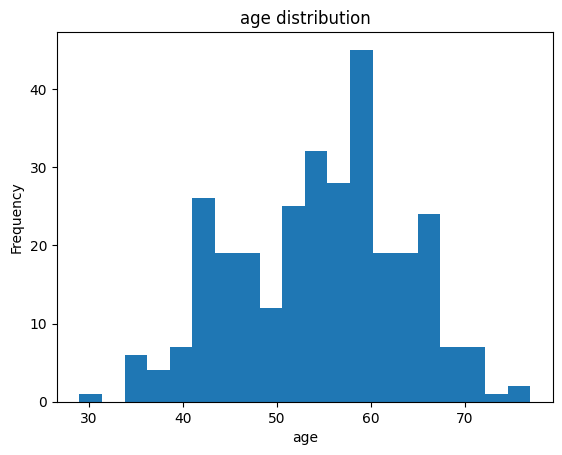

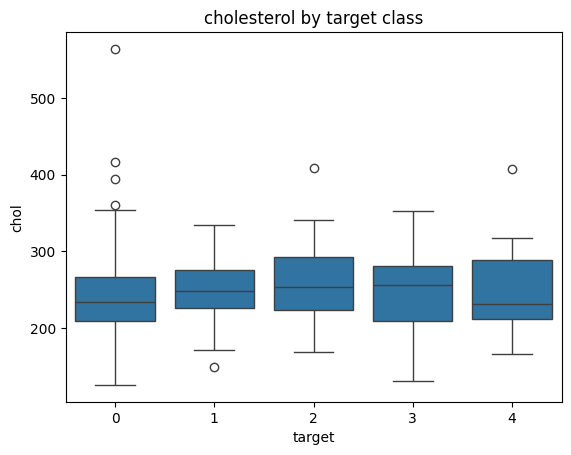

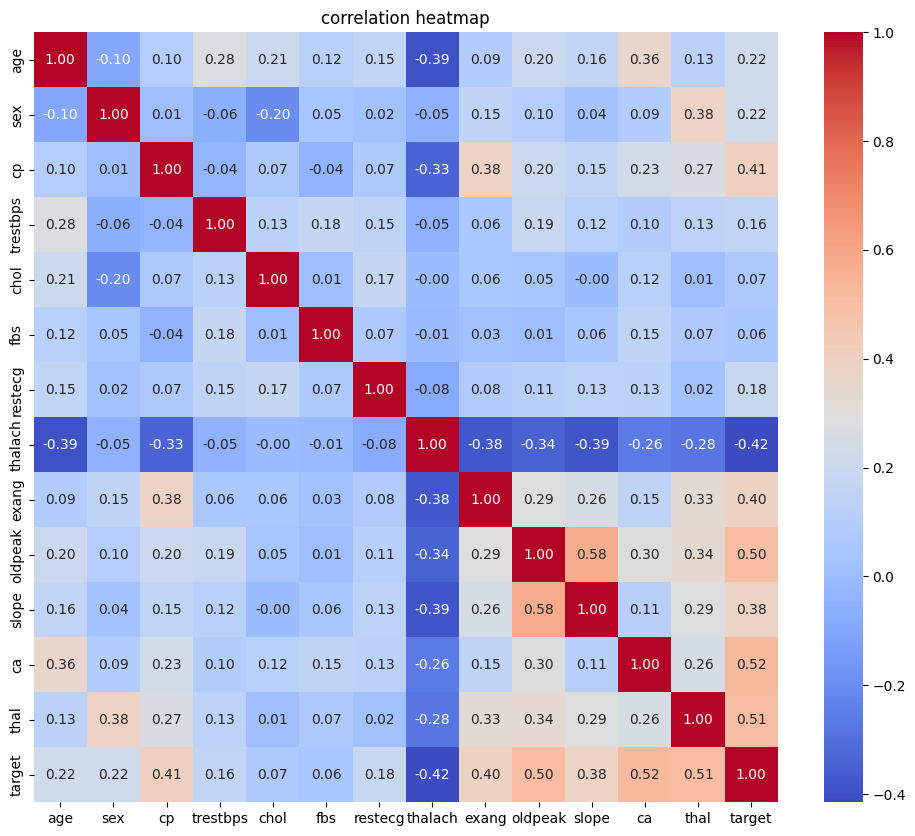

In [16]:
df["target"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("target")
plt.ylabel("count")
plt.title("target distribution")
plt.show()

df["age"].plot(kind="hist", bins=20)
plt.xlabel("age")
plt.title("age distribution")
plt.show()

sns.boxplot(x="target", y="chol", data=df)
plt.xlabel("target")
plt.ylabel("chol")
plt.title("cholesterol by target class")
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("correlation heatmap")
plt.show()

correlation heatmap: ca, thal, oldpeak, and thalach have the strongest link to target. thalach is negative, meaning lower max heart rate is linked to more heart disease. features are not too correlated with each other, so no major duplicate-information problem.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import torch
from torch.utils.data import TensorDataset, DataLoader

# target into binary: 0 = disease nahi, 1 = disease hai
y = (df["target"] > 0).astype(int)
X = df.drop(columns=["target"])

# change cols type ke hisaab se
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

# train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# numerical columns pipeline: missing values fill, phir scale
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

# categorical columns pipeline: missing values fill, phir encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# combine bothh
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# sirf train data pe fit, phir dono pe transform leakage rokne ke liay
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# tensors mein convert
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

# datasets aur loaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |  28     |            |
| Hidden 1 |  64     |    RELU    |
| Hidden 2 |  32     |    RELU    |
| Hidden 3 |  16     |    RELU    |
| Output   |   1     |    SIGMOID |

*(Delete rows you don't use if your design has fewer than 4 hidden layers.)*

In [19]:
print(X_train_tensor.shape)

torch.Size([242, 28])


## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |          28 |            64 | (28 × 64) + 64 |      1,856 |
| Hidden 2 |          64 |            32 | (64 × 32) + 32 |      2,080 |
| Hidden 3 |          32 |            16 | (32 × 16) + 16 |        528 |
| Output   |          16 |             1 | (16 × 1) + 1   |         17 |
| **Total**|             |               |             |      **4,481** |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [20]:
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # input -> hidden 1
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            # hidden 2
            nn.Linear(64, 32),
            nn.ReLU(),

            # hidden 3
            nn.Linear(32, 16),
            nn.ReLU(),

            # output layer
            nn.Linear(16, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


# create model
model = MyModel(
    input_dim=28,
    hidden_dim=64,
    output_dim=1
)

print(model)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [21]:
# TODO: Choose an appropriate loss function
loss_function = nn.BCELoss()


## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [22]:
# TODO: Choose an optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


## Cell 14 — Compile the Model

In [24]:
num_epochs = 100

history = {"train_loss": [], "val_loss": []}

for epoch in range(num_epochs):

    model.train()
    train_losses = []

    for X, y in train_loader:
        optimizer.zero_grad()

        outputs = model(X)
        outputs = outputs.squeeze()

        loss = loss_function(outputs, y)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    model.eval()
    val_losses = []

    with torch.no_grad():
        for X_val, y_val in test_loader:
            outputs = model(X_val)
            outputs = outputs.squeeze()
            loss = loss_function(outputs, y_val)
            val_losses.append(loss.item())

    avg_train_loss = sum(train_losses) / len(train_losses)
    avg_val_loss = sum(val_losses) / len(val_losses)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1}/{num_epochs} - train loss: {avg_train_loss:.4f} - val loss: {avg_val_loss:.4f}")

epoch 10/100 - train loss: 0.4436 - val loss: 0.3518
epoch 20/100 - train loss: 0.2938 - val loss: 0.2600
epoch 30/100 - train loss: 0.2653 - val loss: 0.2678
epoch 40/100 - train loss: 0.1895 - val loss: 0.2850
epoch 50/100 - train loss: 0.1316 - val loss: 0.3311
epoch 60/100 - train loss: 0.0804 - val loss: 0.3974
epoch 70/100 - train loss: 0.0613 - val loss: 0.4668
epoch 80/100 - train loss: 0.0310 - val loss: 0.5147
epoch 90/100 - train loss: 0.0209 - val loss: 0.5715
epoch 100/100 - train loss: 0.0144 - val loss: 0.6101


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

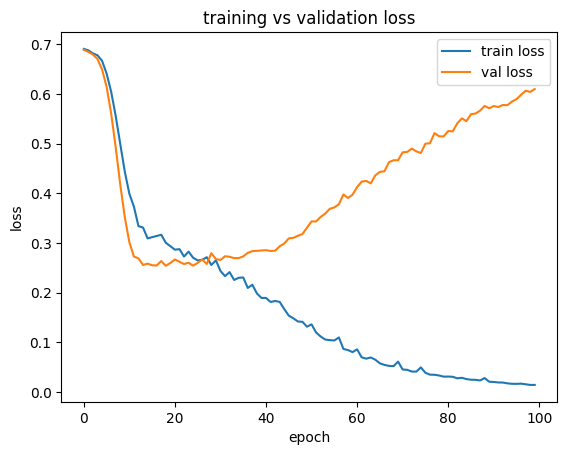

In [25]:
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("training vs validation loss")
plt.legend()
plt.show()

the model is overfitting. train loss and val loss go down together till about epoch 25-30. after that, train loss keeps going down to almost 0, but val loss goes back up to 0.6. this means the model is memorizing the training data instead of learning to generalize.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch

model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)
        probabilities = outputs.squeeze()

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

accuracy = accuracy_score(y_true, y_pred_nn)

precision = precision_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred_nn,
    zero_division=0
)

print(f"accuracy : {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall   : {recall:.4f}")
print(f"f1-score : {f1:.4f}")

accuracy : 0.8361
precision: 0.8214
recall   : 0.8214
f1-score : 0.8214


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [27]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(random_state=42)

ada_model.fit(X_train_processed, y_train)

y_pred_ada = ada_model.predict(X_test_processed)

accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada, zero_division=0)
recall_ada = recall_score(y_test, y_pred_ada, zero_division=0)
f1_ada = f1_score(y_test, y_pred_ada, zero_division=0)

print(f"accuracy : {accuracy_ada:.4f}")
print(f"precision: {precision_ada:.4f}")
print(f"recall   : {recall_ada:.4f}")
print(f"f1-score : {f1_ada:.4f}")

accuracy : 0.8852
precision: 0.8182
recall   : 0.9643
f1-score : 0.8852


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.8361 |    0.8214 | 0.8214 |   0.8214 |
| AdaBoost       |   0.8852 |    0.8182 | 0.9643 |   0.8852 |

Discuss:
- Differences: adaboost has higher accuracy, recall, and f1-score. precision is almost the same for both.
- Possible reasons: adaboost (tree-based) works well on small datasets like this. neural network needs more data, so it struggled more here.
- Overfitting: yes. train loss dropped near 0 but val loss rose after epoch 30 (cell 15), showing the network memorized training data.
- Preprocessing impact: scaling helped the neural network train properly. one-hot encoding raised input size from 13 to 28, adding complexity that may have added to overfitting. adaboost is less affected by scaling since it uses decision trees.

In [28]:
comparison_df = pd.DataFrame({
    "model": ["neural network", "adaboost"],
    "accuracy": [accuracy, accuracy_ada],
    "precision": [precision, precision_ada],
    "recall": [recall, recall_ada],
    "f1-score": [f1, f1_ada]
})

comparison_df

,model,accuracy,precision,recall,f1-score
0,neural network,0.836066,0.821429,0.821429,0.821429
1,adaboost,0.885246,0.818182,0.964286,0.885246


## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work

1. balance: the raw target had 5 classes (0-4) and was imbalanced, with class 0 (no disease) making up 54% of samples and class 4 only 13 samples. after binarizing into disease/no disease, it became closer to balanced (164 vs 139).

2. preprocessing: separated numerical and categorical features, imputed missing values in ca and thal using most frequent value, scaled numerical features with standardscaler, and one-hot encoded categorical features. all fitting was done only on train data to avoid leakage.

3. architecture: used a 5-layer network (28-64-32-16-1) with relu activations in hidden layers and sigmoid on the output for binary classification. adam optimizer and bceloss were used for training.

4. neural network results: accuracy 0.8361, precision 0.8214, recall 0.8214, f1-score 0.8214. the loss plot showed clear overfitting after epoch 30, where val loss increased while train loss kept dropping.

5. adaboost results: accuracy 0.8852, precision 0.8182, recall 0.9643, f1-score 0.8852. adaboost performed strongly, especially in recall, catching most actual disease cases.

6. comparison: adaboost outperformed the neural network on accuracy, recall, and f1-score, with similar precision. this is likely because adaboost handles small tabular datasets better, while the neural network overfit due to limited training data (242 samples).

7. improvements: could use early stopping or dropout to reduce neural network overfitting, try a smaller network, use cross-validation for more reliable metrics, or collect more data to help the neural network generalize better.